# Dataset GeoDAWN : exploration et pipeline actuel

Ce notebook produit une série de figures documentant le pipeline défini par `configs/fault_dataset.yaml` et `configs/train.yaml`. Il ne reprend pas l'ancien protocole à 5 folds de `gems_challenge.ipynb` : le pipeline courant utilise 4 folds de groupes connectés et un holdout géographique 2×2.

Les cartes distinguent explicitement la couverture des covariables, les labels USGS observés, le masque du template et la carte des folds (qui ne couvre que les groupes dilatés). Un label zéro signifie « aucune faille cartographiée dans les labels disponibles », pas une absence géologique certaine.

Depuis la racine du dépôt, exécuter les cellules dans l'ordre. Les PNG sont enregistrés dans `figures/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from hydra import compose, initialize_config_dir
from hydra.utils import instantiate
from matplotlib.colors import ListedColormap
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'configs' / 'fault_dataset.yaml').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Placez le notebook dans le dépôt et exécutez-le depuis celui-ci.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
FIGURES_DIR = ROOT / 'figures'
FIGURES_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'font.size': 9})

with initialize_config_dir(config_dir=str((ROOT / 'configs').resolve()), version_base=None):
    cfg = compose(config_name='train')
features_path = ROOT / str(cfg.data.features_path)
labels_path = ROOT / str(cfg.data.labels_path)
template_path = ROOT / str(cfg.inference.validity_mask_path)

with rasterio.open(features_path) as src:
    profile = src.profile.copy()
    transform = src.transform
    crs = src.crs
    band_names = [description or f'Bande {i + 1:02d}' for i, description in enumerate(src.descriptions)]
    short_band_names = [name.split(' - ', 1)[0] for name in band_names]
    features = src.read(masked=True).filled(np.nan).astype(np.float32, copy=False)
with rasterio.open(labels_path) as src:
    if (src.height, src.width) != features.shape[-2:] or src.transform != transform or src.crs != crs:
        raise ValueError('Les rasters de features et de labels ne partagent pas la même grille.')
    labels_ma = src.read(1, masked=True)
    labels = labels_ma.astype(np.float32).filled(np.nan)
with rasterio.open(template_path) as src:
    if (src.height, src.width) != labels.shape or src.transform != transform or src.crs != crs:
        raise ValueError('Le template de soumission ne partage pas la grille des rasters.')
    template_mask = ~np.ma.getmaskarray(src.read(1, masked=True))

feature_validity = np.isfinite(features).any(axis=0)
label_validity = np.isfinite(labels)
raw_positive = label_validity & (labels == 1)
raw_zero = label_validity & (labels == 0)
holdout_mask = np.zeros(labels.shape, dtype=bool)
if bool(cfg.evaluation.spatial_holdout.enabled):
    from dataops.pretreatment import create_spatial_holdout_mask
    holdout_cfg = cfg.evaluation.spatial_holdout
    holdout_mask = create_spatial_holdout_mask(labels.shape, int(holdout_cfg.grid_rows), int(holdout_cfg.grid_columns), int(holdout_cfg.region_index))

dataset = instantiate(
    cfg.dataset,
    features=features,
    raw_labels=labels,
    transform=tuple(transform),
    scaler_excluded_region_mask=holdout_mask if bool(cfg.evaluation.spatial_holdout.enabled) else None,
)
eligible_train_val = set(dataset.indices_outside_region(holdout_mask)) if holdout_mask.any() else set(range(len(dataset)))
print(f'Raster : {features.shape[2]} × {features.shape[1]} pixels, {features.shape[0]} bandes, {crs}, résolution {profile["transform"].a:g} m')
print(f'Groupes connectés : {dataset.block_count}; folds : {dataset.n_folds}; patch : {dataset.patch_size} × {dataset.patch_size}')
print(f'Pixels avec au moins une covariable valide : {feature_validity.sum():,}')
print(f'Pixels avec label fini : {label_validity.sum():,} (positifs {raw_positive.sum():,}, zéros {raw_zero.sum():,})')
print(f'Pixels valides du template : {template_mask.sum():,}; pixel de holdout : {holdout_mask.sum():,}')
print(f'Groupes éligibles hors holdout pour train/validation : {len(eligible_train_val):,} / {len(dataset):,}')

Raster : 3292 × 3730 pixels, 19 bandes, EPSG:32611, résolution 100 m
Groupes connectés : 544; folds : 4; patch : 128 × 128
Pixels avec au moins une covariable valide : 5,165,852
Pixels avec label fini : 5,167,373 (positifs 60,988, zéros 5,106,385)
Pixels valides du template : 5,167,373; pixel de holdout : 3,069,790
Groupes éligibles hors holdout pour train/validation : 251 / 544


## 1. Vue d'ensemble du traitement

Les flèches représentent l'ordre logique des transformations; les étapes de validité et de holdout restent distinctes des folds de groupes.

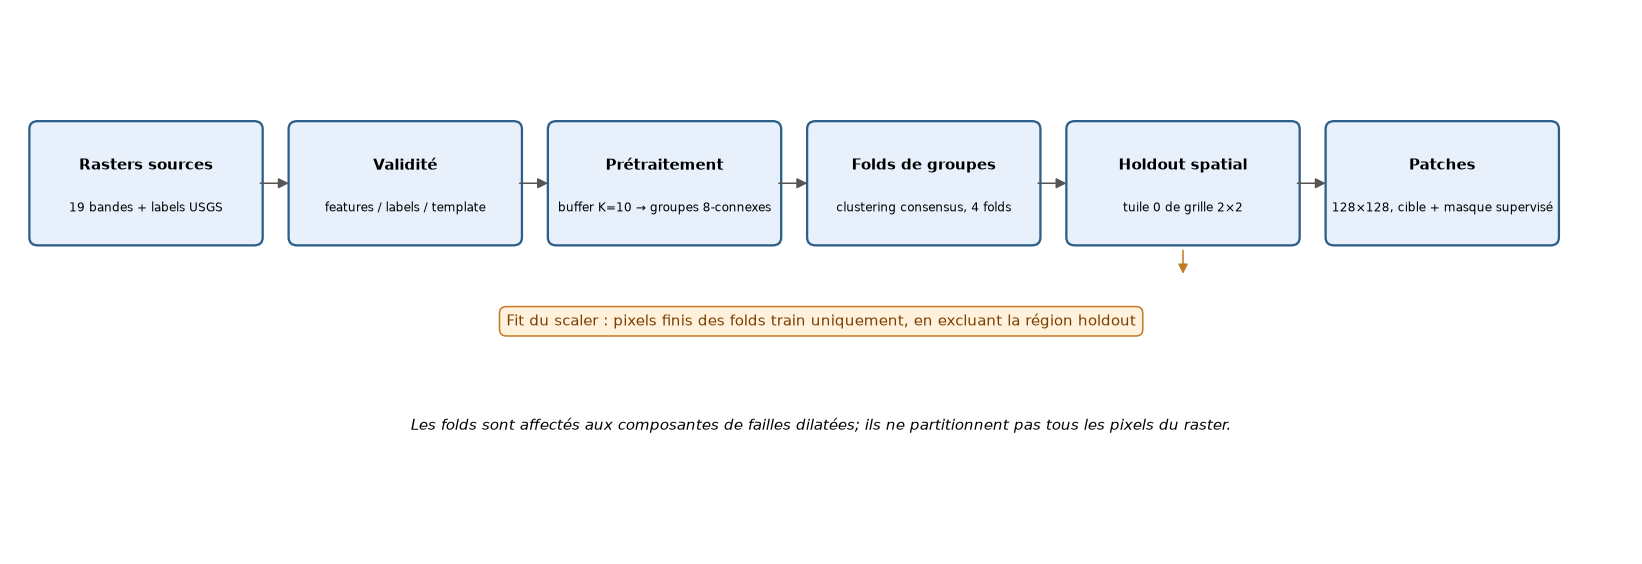

In [2]:
fig, ax = plt.subplots(figsize=(15, 5.2))
ax.set_xlim(0, 15)
ax.set_ylim(0, 5.5)
ax.axis('off')
stages = [
    (0.25, 3.2, 2.0, 1.1, 'Rasters sources', '19 bandes + labels USGS'),
    (2.65, 3.2, 2.0, 1.1, 'Validité', 'features / labels / template'),
    (5.05, 3.2, 2.0, 1.1, 'Prétraitement', 'buffer K=10 → groupes 8-connexes'),
    (7.45, 3.2, 2.0, 1.1, 'Folds de groupes', 'clustering consensus, 4 folds'),
    (9.85, 3.2, 2.0, 1.1, 'Holdout spatial', 'tuile 0 de grille 2×2'),
    (12.25, 3.2, 2.0, 1.1, 'Patches', '128×128, cible + masque supervisé'),
]
for x, y, w, h, title, detail in stages:
    box = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.08', facecolor='#e8f1fb', edgecolor='#2d5f8b', linewidth=1.5)
    ax.add_patch(box)
    ax.text(x + w / 2, y + 0.73, title, ha='center', va='center', weight='bold', fontsize=10)
    ax.text(x + w / 2, y + 0.30, detail, ha='center', va='center', fontsize=8, wrap=True)
for x in [2.28, 4.68, 7.08, 9.48, 11.88]:
    ax.add_patch(FancyArrowPatch((x, 3.75), (x + 0.32, 3.75), arrowstyle='-|>', mutation_scale=14, color='#555'))
ax.text(7.5, 2.35, 'Fit du scaler : pixels finis des folds train uniquement, en excluant la région holdout', ha='center', va='center', fontsize=10, color='#7a3e00', bbox={'boxstyle': 'round,pad=0.45', 'facecolor': '#fff1dc', 'edgecolor': '#c47a25'})
ax.add_patch(FancyArrowPatch((10.85, 3.1), (10.85, 2.8), arrowstyle='-|>', mutation_scale=13, color='#c47a25'))
ax.text(7.5, 1.25, 'Les folds sont affectés aux composantes de failles dilatées; ils ne partitionnent pas tous les pixels du raster.', ha='center', fontsize=10, style='italic')
fig.tight_layout()
fig.savefig(FIGURES_DIR / '01_pipeline_overview.png', bbox_inches='tight')
plt.show()

## 2. Couverture, labels et masque du template

Les trois masques n'ont pas la même signification. Les labels sont ternaires du point de vue de la supervision : faille connue (1), zéro connu (0), et inconnu/NoData.

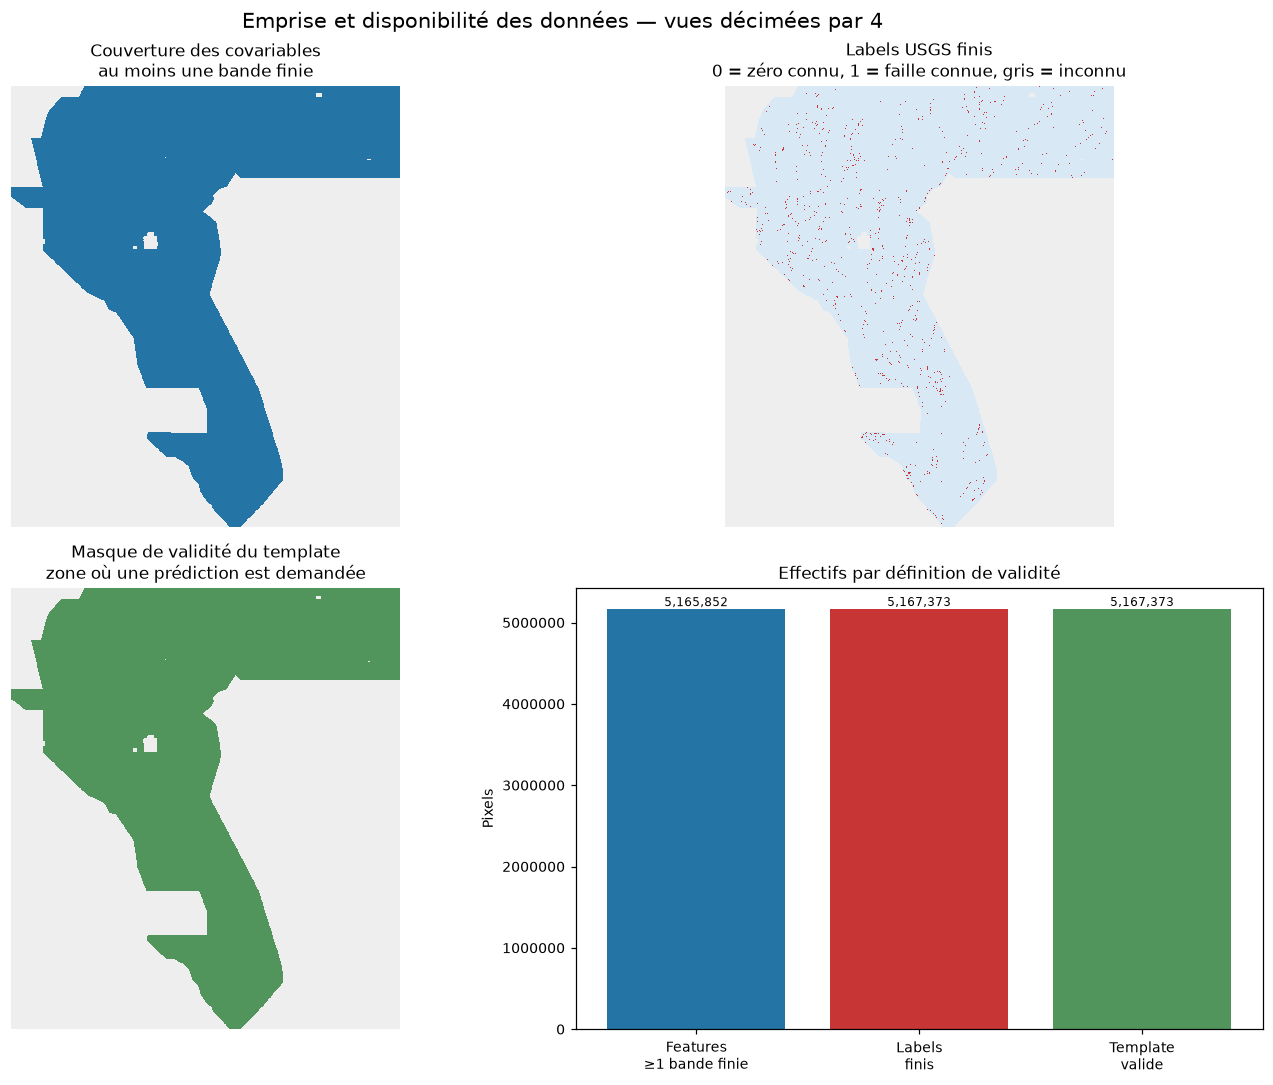

Labels positifs hors couverture feature : 94
Pixels valides du template sans label fini : 0
Pixels labelisés mais hors template : 0


In [3]:
stride = 4
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes[0, 0].imshow(feature_validity[::stride, ::stride], cmap=ListedColormap(['#eeeeee', '#2474a6']), interpolation='nearest')
axes[0, 0].set_title('Couverture des covariables\nau moins une bande finie')
label_classes = np.full(labels.shape, np.nan, dtype=np.float32)
label_classes[raw_zero] = 0
label_classes[raw_positive] = 1
label_cmap = ListedColormap(['#d9e8f5', '#c73535']).with_extremes(bad='#eeeeee')
axes[0, 1].imshow(label_classes[::stride, ::stride], cmap=label_cmap, vmin=0, vmax=1, interpolation='nearest')
axes[0, 1].set_title('Labels USGS finis\n0 = zéro connu, 1 = faille connue, gris = inconnu')
axes[1, 0].imshow(template_mask[::stride, ::stride], cmap=ListedColormap(['#eeeeee', '#51945c']), interpolation='nearest')
axes[1, 0].set_title('Masque de validité du template\nzone où une prédiction est demandée')
counts = [int(feature_validity.sum()), int(label_validity.sum()), int(template_mask.sum())]
names = ['Features\n≥1 bande finie', 'Labels\nfinis', 'Template\nvalide']
bars = axes[1, 1].bar(names, counts, color=['#2474a6', '#c73535', '#51945c'])
axes[1, 1].set_ylabel('Pixels')
axes[1, 1].set_title('Effectifs par définition de validité')
axes[1, 1].ticklabel_format(axis='y', style='plain')
for bar, value in zip(bars, counts):
    axes[1, 1].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{value:,}', ha='center', va='bottom', fontsize=8)
for axis in axes.flat[:3]:
    axis.set_axis_off()
fig.suptitle('Emprise et disponibilité des données — vues décimées par 4', fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '02_coverage_labels_template.png', bbox_inches='tight')
plt.show()

print('Labels positifs hors couverture feature :', int((raw_positive & ~feature_validity).sum()))
print('Pixels valides du template sans label fini :', int((template_mask & ~label_validity).sum()))
print('Pixels labelisés mais hors template :', int((label_validity & ~template_mask).sum()))

## 3. Les 19 bandes géophysiques

Chaque panneau utilise un contraste robuste (quantiles 2–98 %) pour rendre visibles les structures sans laisser les valeurs extrêmes écraser la dynamique.

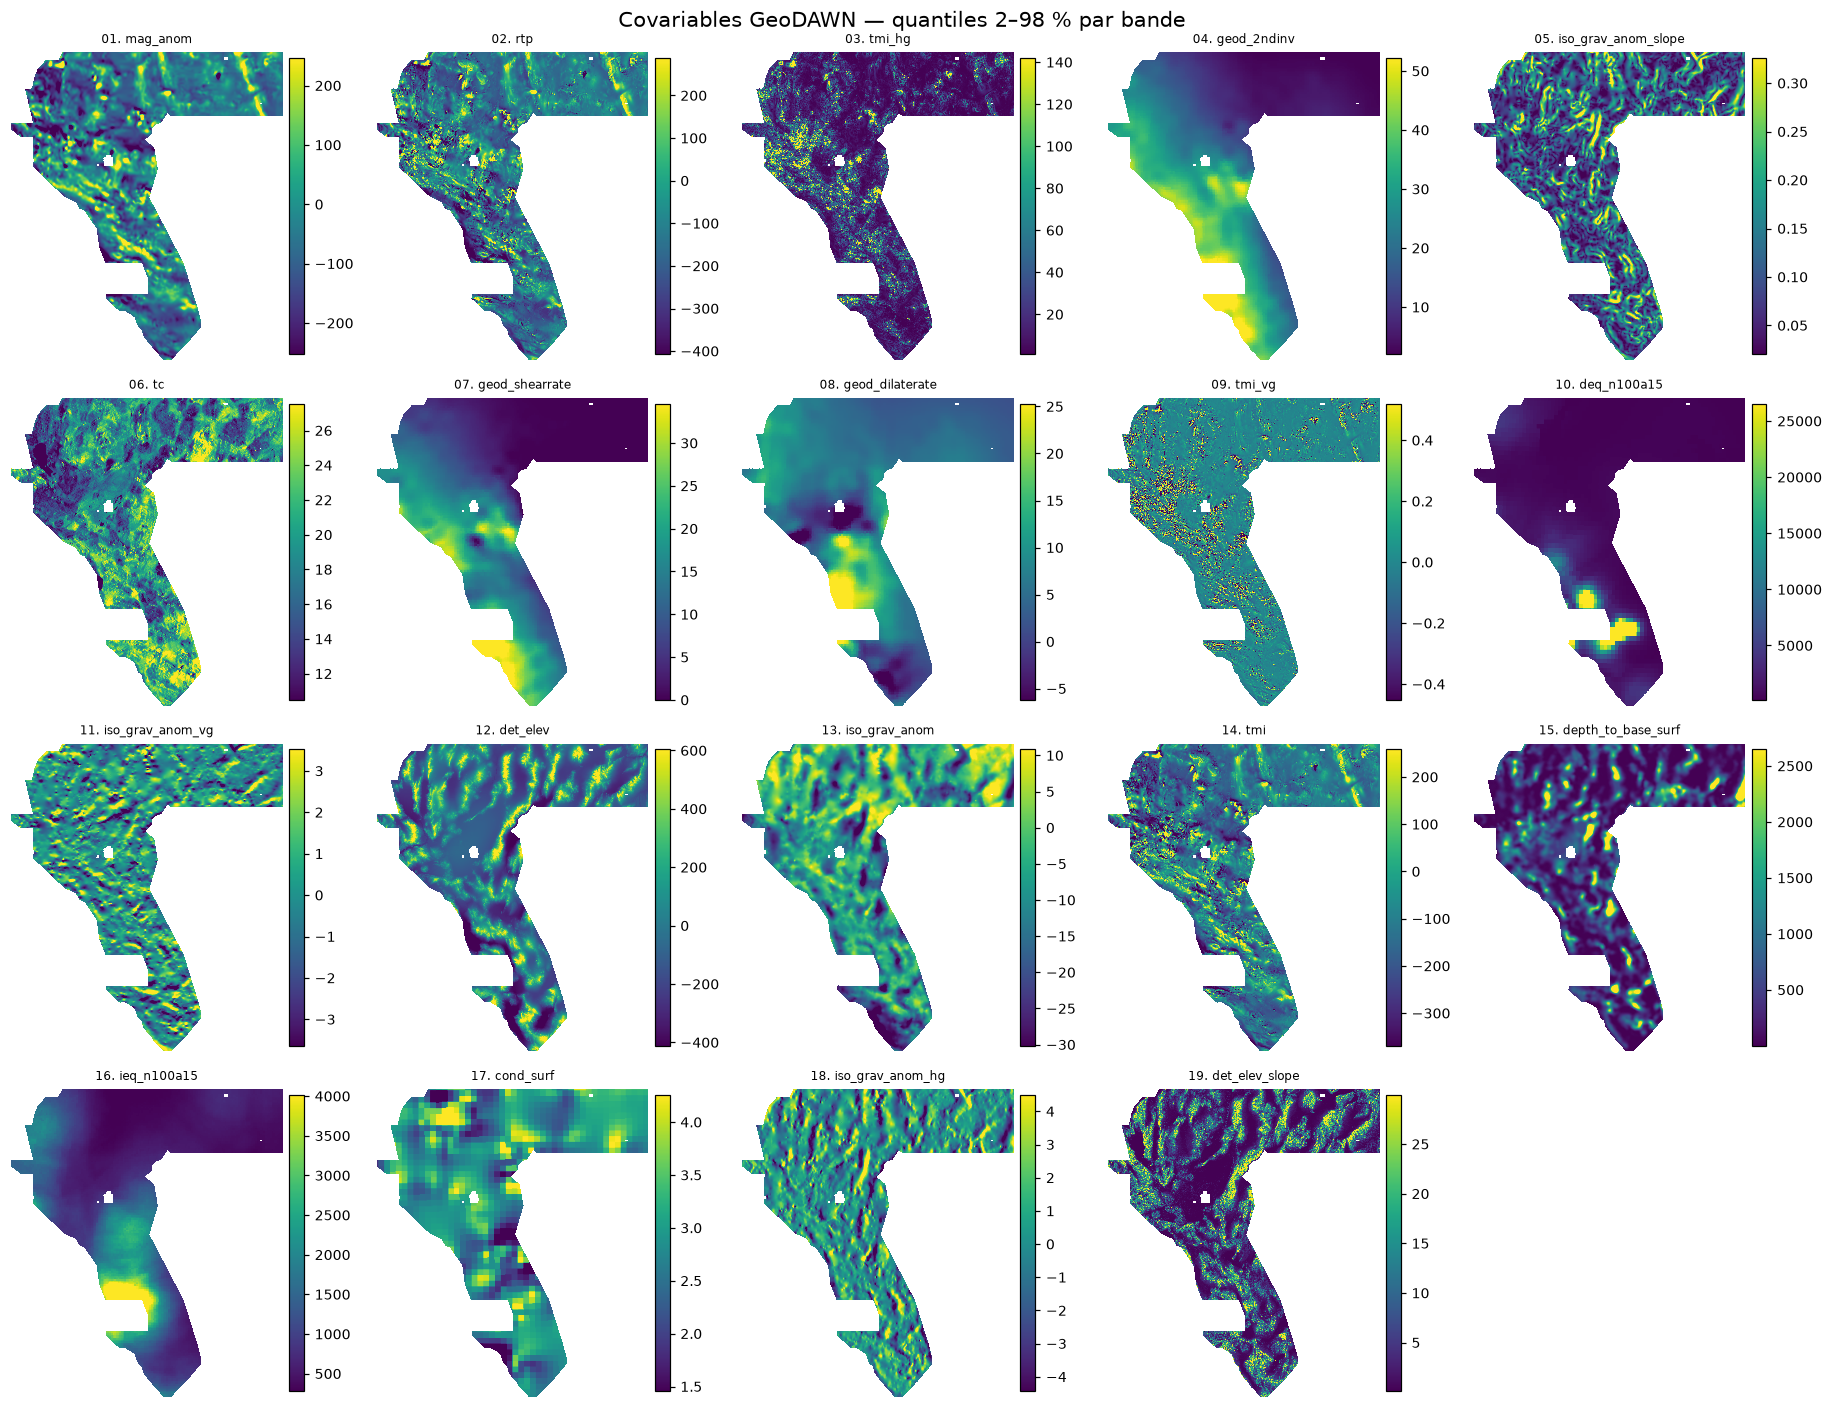

In [4]:
fig, axes = plt.subplots(4, 5, figsize=(17, 13))
for band_id, axis in enumerate(axes.flat[:features.shape[0]]):
    band = features[band_id]
    sample = band[::4, ::4]
    finite = sample[np.isfinite(sample)]
    if finite.size:
        low, high = np.percentile(finite, [2, 98])
        image = axis.imshow(np.ma.masked_invalid(band), cmap='viridis', vmin=low, vmax=high, interpolation='nearest')
        fig.colorbar(image, ax=axis, fraction=0.046, pad=0.02)
    else:
        axis.set_facecolor('#bdbdbd')
    axis.set_title(f'{band_id + 1:02d}. {short_band_names[band_id]}', fontsize=8)
    axis.set_axis_off()
for axis in axes.flat[features.shape[0]:]:
    axis.set_visible(False)
fig.suptitle('Covariables GeoDAWN — quantiles 2–98 % par bande', fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '03_feature_bands_19.png', bbox_inches='tight')
plt.show()

## 4. Qualité des bandes et normalisation

Les histogrammes comparent un échantillon de pixels des groupes train avant/après le scaler. Les statistiques du scaler sont celles du `FaultPatchDataset` réellement construit, ajustées sur les folds train configurés et hors holdout.

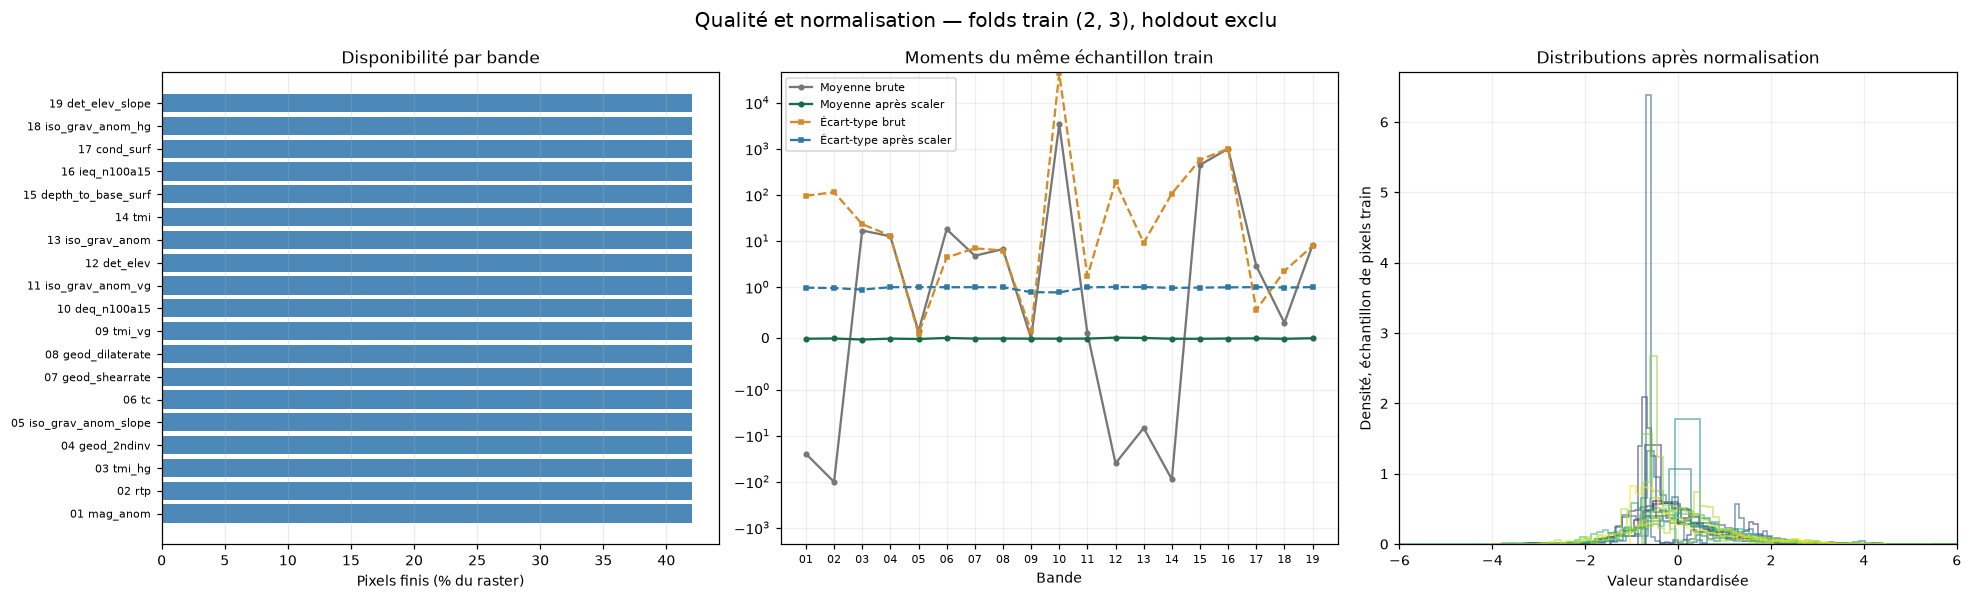

Bande | finitude | moyenne scaler | écart-type scaler
01 mag_anom - Magnetic anomaly   42.070%          -23.997             96.926
02 rtp - Reduced to pole magnet  42.070%           -100.8             116.71
03 tmi_hg - Total magnetic inte  42.070%           17.473             24.347
04 geod_2ndinv - Geodetic secon  42.070%           12.732             13.103
05 iso_grav_anom_slope - Isosta  42.070%          0.13531            0.08734
06 tc - Tilt angle or total cur  42.070%           17.961             4.3983
07 geod_shearrate - Geodetic sh  42.070%           4.8372              6.956
08 geod_dilaterate - Geodetic d  42.070%           6.6713             6.2352
09 tmi_vg - Total magnetic inte  42.070%       -0.0028839            0.15412
10 deq_n100a15 - Distance to ea  42.070%           3740.3              48097
11 iso_grav_anom_vg - Isostatic  42.070%          0.10841             1.7233
12 det_elev - Detrended elevati  42.070%          -42.375             190.86
13 iso_grav_anom - Iso

In [5]:
train_folds = tuple(int(value) for value in cfg.folds.train)
train_pixel_mask = np.isin(dataset.fold_map, train_folds) & ~holdout_mask
sample_stride = 8
train_view = train_pixel_mask[::sample_stride, ::sample_stride]
raw_view = features[:, ::sample_stride, ::sample_stride]
normalized_view = dataset.features[:, ::sample_stride, ::sample_stride].numpy()
band_finite = np.isfinite(raw_view) & train_view[None, :, :]
finite_counts = np.isfinite(features).sum(axis=(1, 2))
finite_fraction = finite_counts / (features.shape[1] * features.shape[2])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
y = np.arange(features.shape[0])
axes[0].barh(y, finite_fraction * 100, color='#4c88b8')
axes[0].set_yticks(y, [f'{i + 1:02d} {name}' for i, name in enumerate(short_band_names)], fontsize=7)
axes[0].set_xlabel('Pixels finis (% du raster)')
axes[0].set_title('Disponibilité par bande')
axes[0].grid(axis='x', alpha=0.25)
raw_means, raw_stds, normalized_means, normalized_stds = [], [], [], []
for band_id in range(features.shape[0]):
    values = raw_view[band_id][band_finite[band_id]]
    scaled = normalized_view[band_id][band_finite[band_id]]
    raw_means.append(float(values.mean()))
    raw_stds.append(float(values.std()))
    normalized_means.append(float(scaled.mean()))
    normalized_stds.append(float(scaled.std()))
x = np.arange(features.shape[0])
axes[1].plot(x, raw_means, 'o-', ms=3, label='Moyenne brute', color='#777777')
axes[1].plot(x, normalized_means, 'o-', ms=3, label='Moyenne après scaler', color='#176b45')
axes[1].plot(x, raw_stds, 's--', ms=3, label='Écart-type brut', color='#d28b26')
axes[1].plot(x, normalized_stds, 's--', ms=3, label='Écart-type après scaler', color='#2e78a3')
axes[1].set_xticks(x, [f'{i + 1:02d}' for i in x], fontsize=7)
axes[1].set_xlabel('Bande')
axes[1].set_title('Moments du même échantillon train')
axes[1].set_yscale('symlog', linthresh=1)
axes[1].legend(fontsize=7)
axes[1].grid(alpha=0.2)
rng = np.random.default_rng(int(cfg.seed))
for band_id in range(features.shape[0]):
    values = raw_view[band_id][band_finite[band_id]]
    scaled = normalized_view[band_id][band_finite[band_id]]
    if values.size > 12000:
        pick = rng.choice(values.size, 12000, replace=False)
        values, scaled = values[pick], scaled[pick]
    axes[2].hist(scaled, bins=45, density=True, histtype='step', linewidth=1.0, alpha=0.65, color=plt.cm.viridis(band_id / max(features.shape[0] - 1, 1)))
axes[2].set_xlim(-6, 6)
axes[2].set_xlabel('Valeur standardisée')
axes[2].set_ylabel('Densité, échantillon de pixels train')
axes[2].set_title('Distributions après normalisation')
axes[2].grid(alpha=0.2)
fig.suptitle(f'Qualité et normalisation — folds train {train_folds}, holdout exclu', fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '04_band_quality_normalization.png', bbox_inches='tight')
plt.show()

print('Bande | finitude | moyenne scaler | écart-type scaler')
for i, (name, fraction, mean, scale) in enumerate(zip(band_names, finite_fraction, dataset.feature_mean, dataset.feature_scale), start=1):
    print(f'{i:02d} {name[:28]:28s} {fraction:8.3%} {mean:16.5g} {scale:18.5g}')

## 5. Labels, buffer et groupes connectés

La dilatation est appliquée aux pixels positifs puis limitée aux labels finis. Les composantes sont ensuite calculées avec une connectivité à 8 voisins.

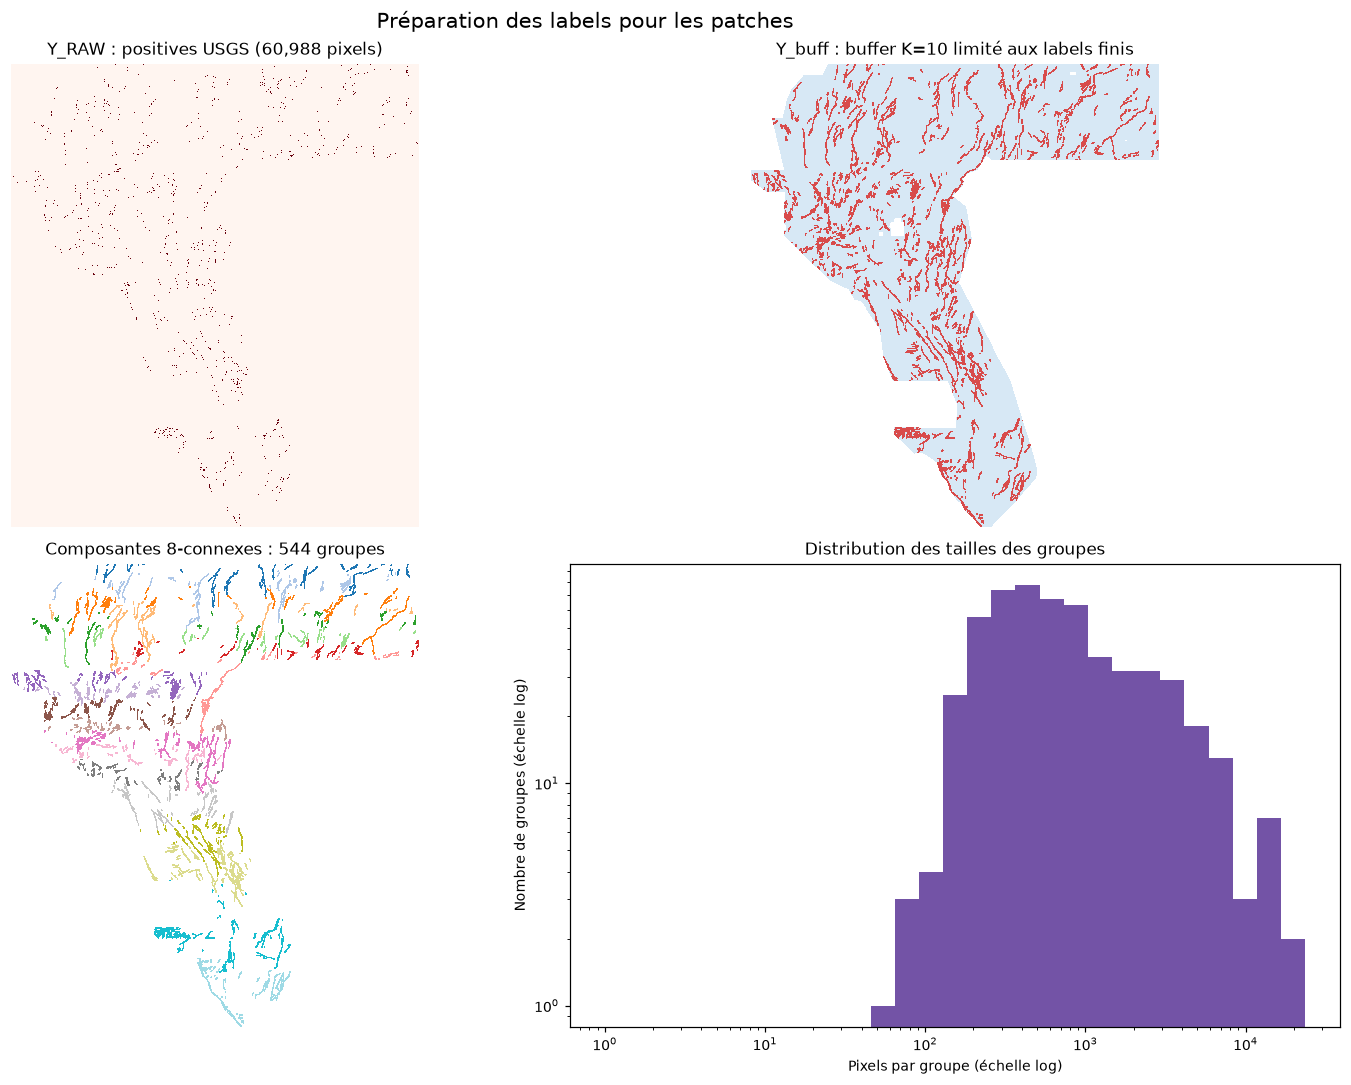

Pixels bufferisés finis : 799,402
Taille des groupes : médiane 600, maximum 23,548 pixels


In [6]:
buffered = dataset.buffered_labels
group_ids = dataset.group_ids
group_sizes = np.bincount(group_ids[np.isfinite(group_ids)].astype(np.int64))[1:]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].imshow(raw_positive[::stride, ::stride], cmap='Reds', interpolation='nearest')
axes[0, 0].set_title(f'Y_RAW : positives USGS ({raw_positive.sum():,} pixels)')
buffer_view = np.ma.masked_where(~np.isfinite(buffered[::stride, ::stride]), buffered[::stride, ::stride])
axes[0, 1].imshow(buffer_view, cmap=ListedColormap(['#d7e8f5', '#d84b4b']), vmin=0, vmax=1, interpolation='nearest')
axes[0, 1].set_title(f'Y_buff : buffer K={int(cfg.KERNEL_SIZE)} limité aux labels finis')
group_view = np.ma.masked_invalid(group_ids[::stride, ::stride])
axes[1, 0].imshow(group_view, cmap='tab20', interpolation='nearest')
axes[1, 0].set_title(f'Composantes 8-connexes : {dataset.block_count} groupes')
positive_sizes = group_sizes[group_sizes > 0]
axes[1, 1].hist(positive_sizes, bins=np.logspace(0, np.log10(max(positive_sizes.max(), 2)), 30), color='#7353a6')
axes[1, 1].set_xscale('log')
axes[1, 1].set_yscale('log')
axes[1, 1].set_xlabel('Pixels par groupe (échelle log)')
axes[1, 1].set_ylabel('Nombre de groupes (échelle log)')
axes[1, 1].set_title('Distribution des tailles des groupes')
for axis in axes.flat[:3]:
    axis.set_axis_off()
fig.suptitle('Préparation des labels pour les patches', fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '05_labels_buffer_groups.png', bbox_inches='tight')
plt.show()
print(f'Pixels bufferisés finis : {int(np.count_nonzero(np.isfinite(buffered) & (buffered == 1))):,}')
print(f'Taille des groupes : médiane {np.median(positive_sizes):,.0f}, maximum {positive_sizes.max():,} pixels')

## 6. Folds, rôles des groupes et holdout géographique

La carte des folds est définie uniquement sur les pixels appartenant aux groupes bufferisés. Le holdout couvre au contraire une tuile géographique entière. Les groupes train/validation dont le groupe ou le patch touche le holdout sont retirés des candidats train/validation.

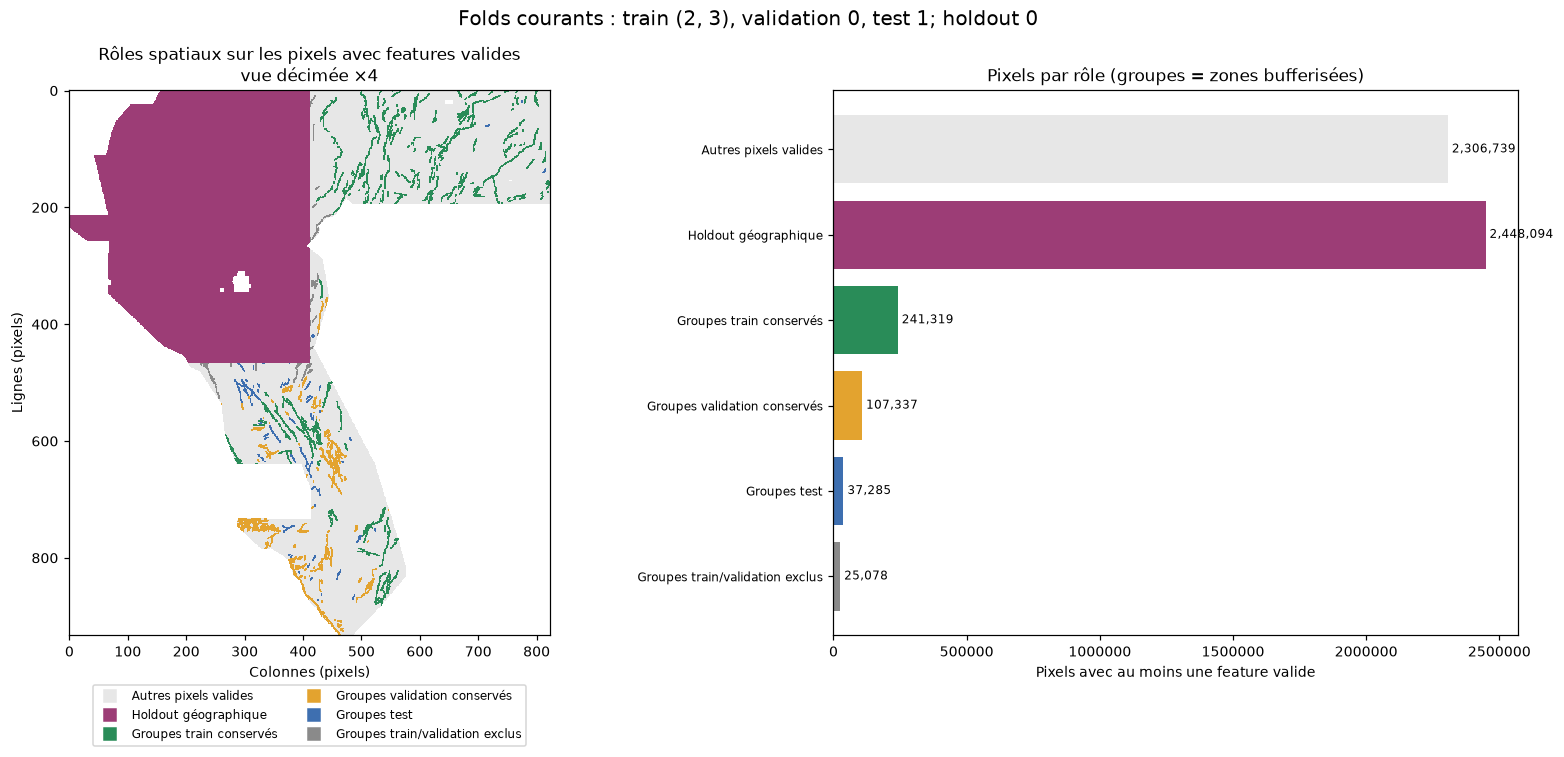

Groupes par fold :
  fold 0: 84 groupes; 56 éligibles hors holdout pour train/validation
  fold 1: 138 groupes; 42 éligibles hors holdout pour train/validation
  fold 2: 161 groupes; 132 éligibles hors holdout pour train/validation
  fold 3: 161 groupes; 21 éligibles hors holdout pour train/validation
Note : les folds ne couvrent que les composantes connectées dilatées, pas le raster entier.


In [7]:
fold_map = dataset.fold_map
folds_train = tuple(int(value) for value in cfg.folds.train)
fold_validation = int(cfg.folds.validation)
fold_test = int(cfg.folds.test)
eligible = eligible_train_val
role_ids = np.zeros(labels.shape, dtype=np.uint8)
role_ids[holdout_mask] = 1
group_pixels = np.isfinite(fold_map)
eligible_group_ids = {dataset._groups[i].group_id for i in eligible}
for index, group in enumerate(dataset._groups):
    gid, fold_id = group.group_id, group.fold_id
    group_mask = group_ids == gid
    if fold_id in folds_train:
        role = 2 if index in eligible else 5
    elif fold_id == fold_validation:
        role = 3 if index in eligible else 5
    elif fold_id == fold_test:
        role = 4
    else:
        raise ValueError(f'Fold {fold_id} non attribué à train/validation/test.')
    role_ids[group_mask & ~holdout_mask] = role

role_names = ['Autres pixels valides', 'Holdout géographique', 'Groupes train conservés', 'Groupes validation conservés', 'Groupes test', 'Groupes train/validation exclus']
role_colors = ['#e7e7e7', '#9c3d76', '#298c58', '#e3a32f', '#3e6fb0', '#8a8a8a']
role_cmap = ListedColormap(role_colors)
role_view = np.ma.masked_where(~feature_validity[::stride, ::stride], role_ids[::stride, ::stride])
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
im = axes[0].imshow(role_view, cmap=role_cmap, vmin=-0.5, vmax=len(role_names) - 0.5, interpolation='nearest')
axes[0].set_title('Rôles spatiaux sur les pixels avec features valides\nvue décimée ×4')
axes[0].set_xlabel('Colonnes (pixels)')
axes[0].set_ylabel('Lignes (pixels)')
handles = [plt.Line2D([0], [0], marker='s', linestyle='', color=color, label=name, markersize=8) for name, color in zip(role_names, role_colors)]
axes[0].legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=8)
pixel_counts = [int((feature_validity & (role_ids == role)).sum()) for role in range(len(role_names))]
bars = axes[1].barh(np.arange(len(role_names)), pixel_counts, color=role_colors)
axes[1].set_yticks(np.arange(len(role_names)), role_names, fontsize=8)
axes[1].invert_yaxis()
axes[1].set_xlabel('Pixels avec au moins une feature valide')
axes[1].set_title('Pixels par rôle (groupes = zones bufferisées)')
axes[1].ticklabel_format(axis='x', style='plain')
for bar, value in zip(bars, pixel_counts):
    axes[1].text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f' {value:,}', va='center', fontsize=8)
fig.suptitle(f'Folds courants : train {folds_train}, validation {fold_validation}, test {fold_test}; holdout {int(cfg.evaluation.spatial_holdout.region_index)}', fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '06_folds_holdout_roles.png', bbox_inches='tight')
plt.show()

print('Groupes par fold :')
for fold_id in range(dataset.n_folds):
    fold_indices = dataset.indices_for_folds((fold_id,))
    kept = sum(i in eligible for i in fold_indices)
    print(f'  fold {fold_id}: {len(fold_indices):,} groupes; {kept:,} éligibles hors holdout pour train/validation')
print('Note : les folds ne couvrent que les composantes connectées dilatées, pas le raster entier.')

## 7. Exemple de patch et masque de supervision

Le patch de 128×128 montre une covariable standardisée, la cible issue des labels originaux, les zéros connus dans le groupe courant, le masque supervisé et la fraction de covariables valides. Les pixels inconnus ne sont pas inclus dans la supervision.

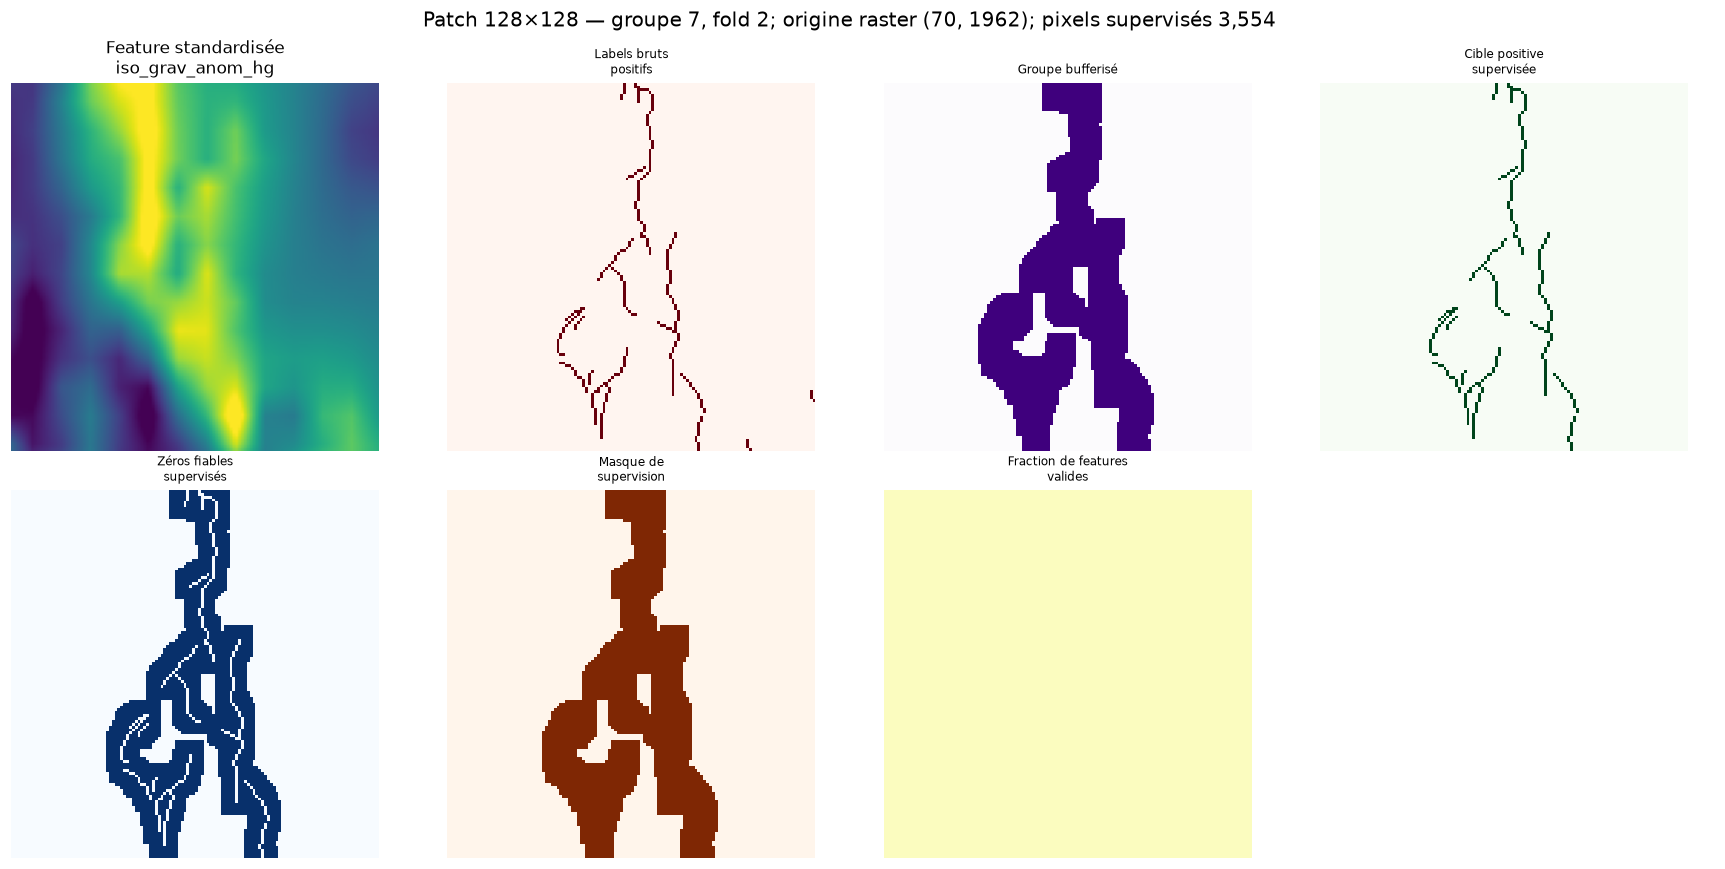

Cible positive : 302 | zéros fiables : 3252 | supervision totale : 3554


In [8]:
sample_index = next((i for i in sorted(eligible) if int(dataset[i]['fold_id']) in folds_train), None)
if sample_index is None:
    raise RuntimeError('Aucun groupe train éligible hors holdout pour illustrer un patch.')
sample = dataset[sample_index]
top, left = (int(value) for value in sample['patch_origin'].tolist())
group_id = int(sample['group_id'])
patch_size = int(dataset.patch_size)
patch_rows = slice(max(top, 0), min(top + patch_size, labels.shape[0]))
patch_cols = slice(max(left, 0), min(left + patch_size, labels.shape[1]))
patch_inside = np.zeros((patch_size, patch_size), dtype=bool)
dst_top, dst_left = max(0, -top), max(0, -left)
dst_bottom, dst_right = dst_top + (patch_rows.stop - patch_rows.start), dst_left + (patch_cols.stop - patch_cols.start)
patch_inside[dst_top:dst_bottom, dst_left:dst_right] = True
raw_patch = np.full((patch_size, patch_size), np.nan, dtype=np.float32)
raw_patch[dst_top:dst_bottom, dst_left:dst_right] = labels[patch_rows, patch_cols]
group_patch = np.zeros((patch_size, patch_size), dtype=bool)
group_patch[dst_top:dst_bottom, dst_left:dst_right] = group_ids[patch_rows, patch_cols] == group_id
target = group_patch & (raw_patch == 1)
reliable_zero = group_patch & (raw_patch == 0)
supervision = target | reliable_zero
feature_patch = sample['features'].numpy()
validity_patch = sample['feature_validity'].numpy()
candidate_band = int(np.argmax(np.nanvar(np.where(validity_patch, feature_patch, np.nan), axis=(1, 2))))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
band = np.ma.masked_where(~validity_patch[candidate_band], feature_patch[candidate_band])
axes[0, 0].imshow(band, cmap='viridis', vmin=np.nanpercentile(band.compressed(), 2), vmax=np.nanpercentile(band.compressed(), 98))
axes[0, 0].set_title(f'Feature standardisée\n{short_band_names[candidate_band]}')
panels = [
    (raw_patch == 1, 'Labels bruts\npositifs', 'Reds'),
    (group_patch, 'Groupe bufferisé', 'Purples'),
    (target, 'Cible positive\nsupervisée', 'Greens'),
    (reliable_zero, 'Zéros fiables\nsupervisés', 'Blues'),
    (supervision, 'Masque de\nsupervision', 'Oranges'),
    (validity_patch.mean(axis=0), 'Fraction de features\nvalides', 'magma'),
]
for axis, (values, title, cmap) in zip(axes.flat[1:], panels):
    axis.imshow(values, cmap=cmap, vmin=0, vmax=1, interpolation='nearest')
    axis.set_title(title, fontsize=8)
for axis in axes.flat:
    axis.set_axis_off()
fig.suptitle(f'Patch {patch_size}×{patch_size} — groupe {group_id}, fold {int(sample["fold_id"])}; origine raster ({top}, {left}); pixels supervisés {int(supervision.sum()):,}', fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '07_patch_supervision_example.png', bbox_inches='tight')
plt.show()
print('Cible positive :', int(target.sum()), '| zéros fiables :', int(reliable_zero.sum()), '| supervision totale :', int(supervision.sum()))

## Fichiers générés

La cellule suivante vérifie la présence de toutes les figures attendues. Les effectifs décrivent les masques et partitions du pipeline courant ; ils ne constituent pas une mesure de qualité prédictive.

In [9]:
expected_names = [
    '01_pipeline_overview.png', '02_coverage_labels_template.png',
    '03_feature_bands_19.png', '04_band_quality_normalization.png',
    '05_labels_buffer_groups.png', '06_folds_holdout_roles.png',
    '07_patch_supervision_example.png',
]
missing_figures = [name for name in expected_names if not (FIGURES_DIR / name).is_file()]
for name in expected_names:
    path = FIGURES_DIR / name
    if path.is_file():
        print(f'{path.name}: {path.stat().st_size:,} octets')
if missing_figures:
    raise RuntimeError(f'Figures absentes : {missing_figures}')
print(f'\nOK — {len(expected_names)} figures enregistrées dans {FIGURES_DIR}')

01_pipeline_overview.png: 84,101 octets
02_coverage_labels_template.png: 103,441 octets
03_feature_bands_19.png: 3,239,061 octets
04_band_quality_normalization.png: 240,962 octets
05_labels_buffer_groups.png: 137,862 octets
06_folds_holdout_roles.png: 143,216 octets
07_patch_supervision_example.png: 102,757 octets

OK — 7 figures enregistrées dans d:\3A_IODAA\gems-challenge\figures
